# 04 - Representation C (time since last measured) + A vs B vs C + error analysis
**Run in Google Colab, after notebooks 02 and 03.** Needs `sepsis_merged.csv`, `repA_train.csv`, `repA_val.csv` in your Drive folder. Expected runtime: roughly 15-30 minutes (12 model fits).

- **A**: imputed values only (from notebook 02)
- **B**: A + `<col>_measured` 0/1 masks (from notebook 03)
- **C**: A + `<col>_since_log` = log(1 + hours since that value was last recorded)

C contains everything B does (since = 0 exactly when the value was measured this hour) plus *how stale* the last value is.
This notebook retrains A and B as well, because the paired bootstrap in section 6 needs all three sets of predictions
on the same validation rows. The test split is deliberately not loaded.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_DIR = '/content/drive/MyDrive/sepsis'

Mounted at /content/drive


In [2]:
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve
from sklearn.utils.class_weight import compute_sample_weight

VITALS = ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2"]
LABS = ["BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2", "AST", "BUN", "Alkalinephos",
        "Calcium", "Chloride", "Creatinine", "Bilirubin_direct", "Glucose", "Lactate",
        "Magnesium", "Phosphate", "Potassium", "Bilirubin_total", "TroponinI", "Hct",
        "Hgb", "PTT", "WBC", "Fibrinogen", "Platelets"]
MASK_COLS = VITALS + LABS
MASK_FEATURES = [f"{c}_measured" for c in MASK_COLS]
SINCE_FEATURES = [f"{c}_since_log" for c in MASK_COLS]
SEEDS = [42, 43, 44]
N_BOOT = 200

## 1. Load Representation A (train + val only)

In [3]:
A_train = pd.read_csv(f"{DRIVE_DIR}/repA_train.csv").sort_values(["patient_id", "hour"]).reset_index(drop=True)
A_val = pd.read_csv(f"{DRIVE_DIR}/repA_val.csv").sort_values(["patient_id", "hour"]).reset_index(drop=True)
print(f"A_train: {A_train.shape}, A_val: {A_val.shape}")

A_train: (1086436, 45), A_val: (231472, 45)


## 2. Build the masks (B) and the time-since features (C) from the RAW data
Rows are sorted by patient and hour, so a per-patient forward fill of "the hour of the last real measurement" gives, for each lab and hour,
how long ago it was last recorded. If a lab has not been recorded yet for that patient, we use the hours observed so far (`hour + 1`).
Time is log-scaled (`log1p`): the difference between 1 h and 3 h stale matters more than between 40 h and 42 h, and it keeps the
linear model's inputs on a sensible scale. Tree models are unaffected by this transform.

In [4]:
raw = pd.read_csv(f"{DRIVE_DIR}/sepsis_merged.csv", usecols=["patient_id", "hour"] + MASK_COLS)
raw = raw.sort_values(["patient_id", "hour"]).reset_index(drop=True)

hours = raw["hour"].to_numpy().astype("float32")[:, None]
measured = raw[MASK_COLS].notna().to_numpy()

# hour of the most recent real measurement at or before each row (per patient)
last = pd.DataFrame(np.where(measured, hours, np.nan).astype("float32"), columns=MASK_COLS)
last = last.groupby(raw["patient_id"])[MASK_COLS].ffill().to_numpy()

since_hours = hours - last                                   # NaN = never measured so far
since_hours = np.where(np.isnan(since_hours), hours + 1, since_hours)

# consistency check: "0 hours since" must be exactly "measured this hour"
assert np.array_equal(since_hours == 0, measured), "time-since and mask disagree"

feat = pd.concat([
    raw[["patient_id", "hour"]],
    pd.DataFrame(measured.astype("int8"), columns=MASK_FEATURES),
    pd.DataFrame(np.log1p(since_hours).astype("float32"), columns=SINCE_FEATURES),
], axis=1)
del raw, last, since_hours, measured, hours

def add_features(a_df):
    out = a_df.merge(feat, on=["patient_id", "hour"], how="left", validate="one_to_one")
    assert len(out) == len(a_df), "row count changed during merge"
    assert out[MASK_FEATURES + SINCE_FEATURES].notna().all().all(), "missing feature values after merge"
    return out

D_train = add_features(A_train)
D_val = add_features(A_val)
print("features added:", len(MASK_FEATURES), "masks +", len(SINCE_FEATURES), "time-since columns")

features added: 34 masks + 34 time-since columns


### Sanity check on one septic patient (first 14 hours)

In [5]:
ex_pid = D_train.loc[D_train["SepsisLabel"] == 1, "patient_id"].iloc[0]
ex = D_train[D_train["patient_id"] == ex_pid].head(14)
show = pd.DataFrame({
    "hour": ex["hour"], "label": ex["SepsisLabel"],
    "Lactate (imputed)": ex["Lactate"].round(2),
    "Lactate_measured": ex["Lactate_measured"],
    "Lactate hours since": np.expm1(ex["Lactate_since_log"]).round(0),
    "Temp hours since": np.expm1(ex["Temp_since_log"]).round(0),
})
print(show.to_string(index=False))

 hour  label  Lactate (imputed)  Lactate_measured  Lactate hours since  Temp hours since
    0      0                2.2                 1                  0.0               1.0
    1      0                2.2                 0                  1.0               0.0
    2      0                2.2                 0                  2.0               0.0
    3      0                2.2                 0                  3.0               1.0
    4      0                2.2                 0                  4.0               2.0
    5      0                2.2                 0                  5.0               3.0
    6      0                2.2                 0                  6.0               0.0
    7      0                2.2                 0                  7.0               1.0
    8      0                2.2                 0                  8.0               2.0
    9      0                2.2                 0                  9.0               3.0
   10      0         

## 3. Train identical models on A, B and C
Same recipe as notebook 03: class-balanced sample weights, threshold 0.5 for F1, Logistic Regression once (deterministic), HistGradientBoosting for 3 seeds.
Validation probabilities from the first seed are kept for the bootstrap and the error analysis.

In [6]:
BASE_FEATURES = [c for c in A_train.columns if c not in ("patient_id", "SepsisLabel")]
FEATURE_SETS = {"A": BASE_FEATURES,
                "B": BASE_FEATURES + MASK_FEATURES,
                "C": BASE_FEATURES + SINCE_FEATURES}
print({k: len(v) for k, v in FEATURE_SETS.items()}, "features")

y_train, y_val = D_train["SepsisLabel"], D_val["SepsisLabel"]
sample_weight = compute_sample_weight(class_weight="balanced", y=y_train)

def score(probs):
    return dict(pr_auc=average_precision_score(y_val, probs),
                f1=f1_score(y_val, (probs >= 0.5).astype(int)))

results, probs = [], {}
for rep, cols in FEATURE_SETS.items():
    X_tr, X_va = D_train[cols], D_val[cols]

    scaler = StandardScaler().fit(X_tr)
    logreg = LogisticRegression(max_iter=1000, random_state=42)
    logreg.fit(scaler.transform(X_tr), y_train, sample_weight=sample_weight)
    p = logreg.predict_proba(scaler.transform(X_va))[:, 1]
    probs[(rep, "LogisticRegression")] = p
    results.append(dict(rep=rep, model="LogisticRegression", seed=42, **score(p)))
    print(f"[{rep}] LogisticRegression done")

    for seed in SEEDS:
        hgb = HistGradientBoostingClassifier(random_state=seed)
        hgb.fit(X_tr, y_train, sample_weight=sample_weight)
        p = hgb.predict_proba(X_va)[:, 1]
        if seed == SEEDS[0]:
            probs[(rep, "HistGradientBoosting")] = p
        results.append(dict(rep=rep, model="HistGradientBoosting", seed=seed, **score(p)))
        print(f"[{rep}] HistGradientBoosting seed={seed} done")

res = pd.DataFrame(results)

{'A': 43, 'B': 77, 'C': 77} features
[A] LogisticRegression done
[A] HistGradientBoosting seed=42 done
[A] HistGradientBoosting seed=43 done
[A] HistGradientBoosting seed=44 done
[B] LogisticRegression done
[B] HistGradientBoosting seed=42 done
[B] HistGradientBoosting seed=43 done
[B] HistGradientBoosting seed=44 done
[C] LogisticRegression done
[C] HistGradientBoosting seed=42 done
[C] HistGradientBoosting seed=43 done
[C] HistGradientBoosting seed=44 done


## 4. A vs B vs C

In [7]:
def mean_std(g, col):
    m, s = g[col].mean(), g[col].std()
    return f"{m:.4f}" + (f" +/- {s:.4f}" if len(g) > 1 else "")

print(f"{'Model':<22}{'Rep':<5}{'PR-AUC':<20}{'F1 @0.5':<20}{'runs'}")
for (model, rep), g in res.groupby(["model", "rep"]):
    print(f"{model:<22}{rep:<5}{mean_std(g, 'pr_auc'):<20}{mean_std(g, 'f1'):<20}{len(g)}")

print("\nHistGradientBoosting, PR-AUC per seed (paired: same seed, same data, only the features differ):")
piv = res[res.model == "HistGradientBoosting"].pivot(index="seed", columns="rep", values="pr_auc")
piv["B-A"], piv["C-A"], piv["C-B"] = piv["B"] - piv["A"], piv["C"] - piv["A"], piv["C"] - piv["B"]
print(piv.round(4).to_string())

Model                 Rep  PR-AUC              F1 @0.5             runs
HistGradientBoosting  A    0.0869 +/- 0.0033   0.1124 +/- 0.0011   3
HistGradientBoosting  B    0.0900 +/- 0.0016   0.1150 +/- 0.0007   3
HistGradientBoosting  C    0.0933 +/- 0.0020   0.1180 +/- 0.0020   3
LogisticRegression    A    0.0686              0.0775              1
LogisticRegression    B    0.0750              0.0862              1
LogisticRegression    C    0.0844              0.0969              1

HistGradientBoosting, PR-AUC per seed (paired: same seed, same data, only the features differ):
rep        A       B       C     B-A     C-A     C-B
seed                                                
42    0.0886  0.0888  0.0910  0.0002  0.0024  0.0022
43    0.0891  0.0919  0.0941  0.0028  0.0050  0.0022
44    0.0831  0.0894  0.0948  0.0063  0.0117  0.0053


## 5. Paired patient-level bootstrap on the validation set
We resample *validation patients* with replacement (never single rows, since rows of one patient are correlated), recompute PR-AUC for A, B and C
on the same resample, and look at the distribution of the differences. If the 95% interval includes 0, the difference cannot be claimed.
This captures which validation patients happened to be sampled; the per-seed table above captures training randomness. Uses the seed-42 models.

In [8]:
y = y_val.to_numpy()
pid = D_val["patient_id"].to_numpy()
order = np.argsort(pid, kind="stable")
_, starts, counts = np.unique(pid[order], return_index=True, return_counts=True)
rows_by_patient = [order[s:s + c] for s, c in zip(starts, counts)]

def pr_auc(y_true, p):
    return average_precision_score(y_true, p)

rng = np.random.default_rng(0)
boot = {k: [] for k in probs}
for _ in range(N_BOOT):
    pick = rng.integers(0, len(rows_by_patient), len(rows_by_patient))
    rows = np.concatenate([rows_by_patient[i] for i in pick])
    for k, p in probs.items():
        boot[k].append(pr_auc(y[rows], p[rows]))

full = {k: pr_auc(y, p) for k, p in probs.items()}
for model in ("LogisticRegression", "HistGradientBoosting"):
    print(model)
    for x, z in [("B", "A"), ("C", "A"), ("C", "B")]:
        d = np.array(boot[(x, model)]) - np.array(boot[(z, model)])
        lo, hi = np.percentile(d, [2.5, 97.5])
        verdict = "excludes 0" if (lo > 0 or hi < 0) else "includes 0"
        print(f"  {x} - {z}: {full[(x, model)] - full[(z, model)]:+.4f}   95% CI [{lo:+.4f}, {hi:+.4f}]   {verdict}")

LogisticRegression
  B - A: +0.0064   95% CI [+0.0004, +0.0095]   excludes 0
  C - A: +0.0159   95% CI [+0.0082, +0.0237]   excludes 0
  C - B: +0.0094   95% CI [+0.0041, +0.0192]   excludes 0
HistGradientBoosting
  B - A: +0.0002   95% CI [-0.0072, +0.0069]   includes 0
  C - A: +0.0024   95% CI [-0.0072, +0.0106]   includes 0
  C - B: +0.0022   95% CI [-0.0055, +0.0100]   includes 0


## 6. Error analysis on the best model
Picks the best (representation, model) by validation PR-AUC (seed-42 run) and fixes one operating threshold, the one that maximises F1 on the validation rows.
This threshold is tuned on the same data it is evaluated on, so the numbers below describe behaviour for the analysis; they are not a final performance estimate.

In [9]:
best = max(full, key=full.get)
p_best = probs[best]
prec, rec, thr = precision_recall_curve(y, p_best)
f1_curve = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
thr_star = thr[np.argmax(f1_curve)]
print(f"best = {best}, PR-AUC = {full[best]:.4f}")
print(f"operating threshold = {thr_star:.3f}  ->  row-level precision {prec[np.argmax(f1_curve)]:.3f}, "
      f"recall {rec[np.argmax(f1_curve)]:.3f}, F1 {f1_curve.max():.3f}")

print("\nPer hospital (validation rows):")
for h in ("A", "B"):
    m = D_val[f"hosp_{h}"].to_numpy().astype(bool)
    print(f"  hospital {h}: {m.sum():7,d} rows, positive rate {100 * y[m].mean():.2f}%, PR-AUC {pr_auc(y[m], p_best[m]):.4f}")

best = ('C', 'HistGradientBoosting'), PR-AUC = 0.0910
operating threshold = 0.790  ->  row-level precision 0.123, recall 0.289, F1 0.173

Per hospital (validation rows):
  hospital A: 119,317 rows, positive rate 2.18%, PR-AUC 0.0942
  hospital B: 112,155 rows, positive rate 1.39%, PR-AUC 0.0854


In [10]:
ev = D_val[["patient_id", "hour", "SepsisLabel"]].copy()
ev["alert"] = p_best >= thr_star

t0 = ev[ev.SepsisLabel == 1].groupby("patient_id")["hour"].min()        # first hour labelled positive
first_alert = ev[ev.alert].groupby("patient_id")["hour"].min()
s = pd.DataFrame({"t0": t0}).join(first_alert.rename("first_alert"))
detected = s["first_alert"].notna()
early = s["first_alert"] <= s["t0"]
lead = (s["t0"] - s["first_alert"])[detected]

print(f"Septic patients in validation: {len(s)}")
print(f"  alerted at least once          : {detected.sum()} ({100 * detected.mean():.1f}%)")
print(f"  alerted at/before label start  : {early.sum()} ({100 * early.mean():.1f}%)")
print(f"  missed completely              : {(~detected).sum()} ({100 * (~detected).mean():.1f}%)")
print(f"  median lead time (hours before label start, negative = late): {lead.median():.1f}")

non = ev[~ev["patient_id"].isin(s.index)]
pct_patients = 100 * non.groupby("patient_id")["alert"].max().mean()
per_24h = 24 * non["alert"].mean()
print(f"\nNon-septic patients: {pct_patients:.1f}% trigger at least one alert; "
      f"{per_24h:.1f} alert-hours per 24 patient-hours")

Septic patients in validation: 440
  alerted at least once          : 203 (46.1%)
  alerted at/before label start  : 154 (35.0%)
  missed completely              : 237 (53.9%)
  median lead time (hours before label start, negative = late): 20.0

Non-septic patients: 5.8% trigger at least one alert; 0.3 alert-hours per 24 patient-hours


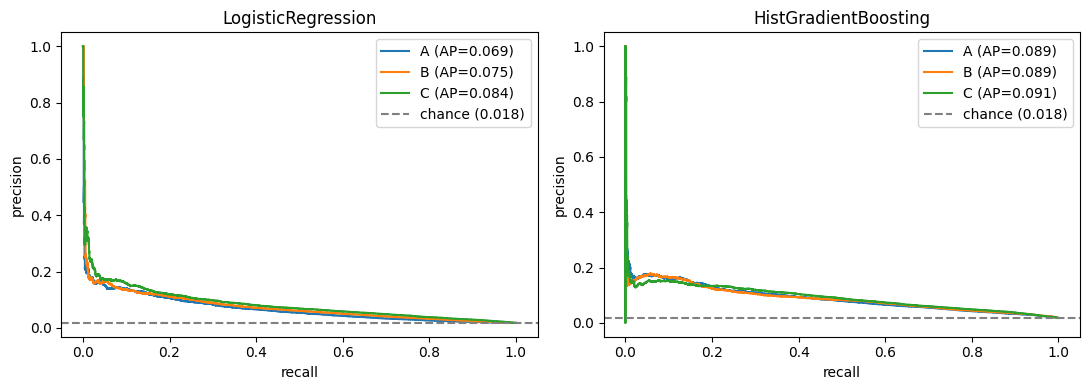

saved pr_curves_ABC.png in your Drive folder - copy it to results/figures/ in the repo


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, model in zip(axes, ["LogisticRegression", "HistGradientBoosting"]):
    for rep in "ABC":
        pr, rc, _ = precision_recall_curve(y, probs[(rep, model)])
        ax.plot(rc, pr, label=f"{rep} (AP={full[(rep, model)]:.3f})")
    ax.axhline(y.mean(), ls="--", c="gray", label=f"chance ({y.mean():.3f})")
    ax.set_title(model); ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.legend()
plt.tight_layout()
plt.savefig(f"{DRIVE_DIR}/pr_curves_ABC.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved pr_curves_ABC.png in your Drive folder - copy it to results/figures/ in the repo")

## 7. Rows to paste into `results_log.md`

In [12]:
for (model, rep), g in res.groupby(["model", "rep"]):
    print(f"| {rep} | {model} | {g.pr_auc.mean():.4f} | {g.f1.mean():.4f} |  | "
          f"val set, thr=0.5, mean of {len(g)} run(s) | |")

| A | HistGradientBoosting | 0.0869 | 0.1124 |  | val set, thr=0.5, mean of 3 run(s) | |
| B | HistGradientBoosting | 0.0900 | 0.1150 |  | val set, thr=0.5, mean of 3 run(s) | |
| C | HistGradientBoosting | 0.0933 | 0.1180 |  | val set, thr=0.5, mean of 3 run(s) | |
| A | LogisticRegression | 0.0686 | 0.0775 |  | val set, thr=0.5, mean of 1 run(s) | |
| B | LogisticRegression | 0.0750 | 0.0862 |  | val set, thr=0.5, mean of 1 run(s) | |
| C | LogisticRegression | 0.0844 | 0.0969 |  | val set, thr=0.5, mean of 1 run(s) | |
